In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold, cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import PowerTransformer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.impute import KNNImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import optuna


In [2]:
df = pd.read_csv(r"C:\Users\PALWAI MEGHNA\Desktop\Innomatics\swiggy_demographic.csv")
df

,rider_id,age,ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_date,weather,traffic,...,time_taken,city_name,order_day,order_month,order_day_of_week,is_weekend,pickup_time_minutes,order_time_hour,order_time_of_day,distance
0,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,sunny,high,...,24,INDO,19,3,saturday,1,15.0,11.0,morning,3.025149
1,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,stormy,jam,...,33,BANG,25,3,friday,0,5.0,19.0,evening,20.183530
2,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,sandstorms,low,...,26,BANG,19,3,saturday,1,15.0,8.0,morning,1.552758
3,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,sunny,medium,...,21,COIMB,5,4,tuesday,0,10.0,18.0,evening,7.790401
4,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,cloudy,high,...,30,CHEN,26,3,saturday,1,15.0,13.0,afternoon,6.210138
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45497,JAPRES04DEL01,30.0,4.8,26.902328,75.794257,26.912328,75.804257,2022-03-24,windy,high,...,32,JAP,24,3,thursday,0,10.0,11.0,morning,1.489846
45498,AGRRES16DEL01,21.0,4.6,NaN,NaN,NaN,NaN,2022-02-16,windy,jam,...,36,AGR,16,2,wednesday,0,15.0,19.0,evening,NaN
45499,CHENRES08DEL03,30.0,4.9,13.022394,80.242439,13.052394,80.272439,2022-03-11,cloudy,low,...,16,CHEN,11,3,friday,0,15.0,23.0,night,4.657195
45500,COIMBRES11DEL01,20.0,4.7,11.001753,76.986241,11.041753,77.026241,2022-03-07,cloudy,high,...,26,COIMB,7,3,monday,0,5.0,13.0,afternoon,6.232393


# Understanding data

In [3]:
df.shape

(45502, 26)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45502 entries, 0 to 45501
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   rider_id              45502 non-null  object 
 1   age                   43648 non-null  float64
 2   ratings               43594 non-null  float64
 3   restaurant_latitude   41872 non-null  float64
 4   restaurant_longitude  41872 non-null  float64
 5   delivery_latitude     41872 non-null  float64
 6   delivery_longitude    41872 non-null  float64
 7   order_date            45502 non-null  object 
 8   weather               44977 non-null  object 
 9   traffic               44992 non-null  object 
 10  vehicle_condition     45502 non-null  int64  
 11  type_of_order         45502 non-null  object 
 12  type_of_vehicle       45502 non-null  object 
 13  multiple_deliveries   44509 non-null  float64
 14  festival              45274 non-null  object 
 15  city_type          

In [5]:
df.describe()

,age,ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,vehicle_condition,multiple_deliveries,time_taken,order_day,order_month,is_weekend,pickup_time_minutes,order_time_hour,distance
count,43648.000000,43594.000000,41872.000000,41872.000000,41872.000000,41872.000000,45502.000000,44509.000000,45502.000000,45502.000000,45502.000000,45502.000000,43862.000000,43862.000000,41872.000000
mean,29.555008,4.635287,18.913696,76.921664,18.977356,76.985325,1.019406,0.744928,26.297591,13.811657,2.980726,0.274867,9.989399,17.423966,9.719296
std,5.761482,0.313827,5.467265,3.503107,5.469056,3.503260,0.835229,0.572488,9.386419,8.709540,0.546031,0.446452,4.087516,4.817856,5.602890
min,20.000000,2.500000,9.957144,72.768726,9.967144,72.778726,0.000000,0.000000,10.000000,1.000000,2.000000,0.000000,5.000000,0.000000,1.465067
25%,25.000000,4.500000,12.986047,73.897902,13.065996,73.940327,0.000000,0.000000,19.000000,6.000000,3.000000,0.000000,5.000000,15.000000,4.657655
50%,30.000000,4.700000,19.065838,76.618203,19.124049,76.662620,1.000000,1.000000,26.000000,13.000000,3.000000,0.000000,10.000000,19.000000,9.193014
75%,35.000000,4.900000,22.751234,78.368855,22.820040,78.405467,2.000000,1.000000,32.000000,20.000000,3.000000,1.000000,15.000000,21.000000,13.680920
max,39.000000,5.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000,31.000000,4.000000,1.000000,15.000000,23.000000,20.969489


In [6]:
df.describe(include='object')

,rider_id,order_date,weather,traffic,type_of_order,type_of_vehicle,festival,city_type,city_name,order_day_of_week,order_time_of_day
count,45502,45502,44977,44992,45502,45502,45274,44304,45502,45502,45502
unique,1320,44,6,4,4,4,2,3,22,7,5
top,PUNERES01DEL01,2022-03-15,fog,low,snack,motorcycle,no,metropolitian,JAP,wednesday,night
freq,67,1190,7654,15477,11512,26427,44380,34029,3439,7077,18312


In [7]:
df.columns

Index(['rider_id', 'age', 'ratings', 'restaurant_latitude',
       'restaurant_longitude', 'delivery_latitude', 'delivery_longitude',
       'order_date', 'weather', 'traffic', 'vehicle_condition',
       'type_of_order', 'type_of_vehicle', 'multiple_deliveries', 'festival',
       'city_type', 'time_taken', 'city_name', 'order_day', 'order_month',
       'order_day_of_week', 'is_weekend', 'pickup_time_minutes',
       'order_time_hour', 'order_time_of_day', 'distance'],
      dtype='object')

In [8]:
df.dtypes

rider_id                 object
age                     float64
ratings                 float64
restaurant_latitude     float64
restaurant_longitude    float64
delivery_latitude       float64
delivery_longitude      float64
order_date               object
weather                  object
traffic                  object
vehicle_condition         int64
type_of_order            object
type_of_vehicle          object
multiple_deliveries     float64
festival                 object
city_type                object
time_taken                int64
city_name                object
order_day                 int64
order_month               int64
order_day_of_week        object
is_weekend                int64
pickup_time_minutes     float64
order_time_hour         float64
order_time_of_day        object
distance                float64
dtype: object

In [9]:
df.drop(columns=['rider_id', 'order_date'], inplace= True)

In [10]:
# numeric columns
num_cols = df.select_dtypes(include="number").columns
num_cols

Index(['age', 'ratings', 'restaurant_latitude', 'restaurant_longitude',
       'delivery_latitude', 'delivery_longitude', 'vehicle_condition',
       'multiple_deliveries', 'time_taken', 'order_day', 'order_month',
       'is_weekend', 'pickup_time_minutes', 'order_time_hour', 'distance'],
      dtype='object')

In [11]:
# categorical columns
cat_cols = df.select_dtypes(include="object").columns
cat_cols

Index(['weather', 'traffic', 'type_of_order', 'type_of_vehicle', 'festival',
       'city_type', 'city_name', 'order_day_of_week', 'order_time_of_day'],
      dtype='object')

In [12]:
df.head(1)

,age,ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,weather,traffic,vehicle_condition,type_of_order,...,time_taken,city_name,order_day,order_month,order_day_of_week,is_weekend,pickup_time_minutes,order_time_hour,order_time_of_day,distance
0,37.0,4.9,22.745049,75.892471,22.765049,75.912471,sunny,high,2,snack,...,24,INDO,19,3,saturday,1,15.0,11.0,morning,3.025149


In [13]:
df.isnull().sum()

age                     1854
ratings                 1908
restaurant_latitude     3630
restaurant_longitude    3630
delivery_latitude       3630
delivery_longitude      3630
weather                  525
traffic                  510
vehicle_condition          0
type_of_order              0
type_of_vehicle            0
multiple_deliveries      993
festival                 228
city_type               1198
time_taken                 0
city_name                  0
order_day                  0
order_month                0
order_day_of_week          0
is_weekend                 0
pickup_time_minutes     1640
order_time_hour         1640
order_time_of_day          0
distance                3630
dtype: int64

In [14]:
(df.isnull().sum() / len(df))*100

age                     4.074546
ratings                 4.193222
restaurant_latitude     7.977671
restaurant_longitude    7.977671
delivery_latitude       7.977671
delivery_longitude      7.977671
weather                 1.153795
traffic                 1.120830
vehicle_condition       0.000000
type_of_order           0.000000
type_of_vehicle         0.000000
multiple_deliveries     2.182322
festival                0.501077
city_type               2.632851
time_taken              0.000000
city_name               0.000000
order_day               0.000000
order_month             0.000000
order_day_of_week       0.000000
is_weekend              0.000000
pickup_time_minutes     3.604237
order_time_hour         3.604237
order_time_of_day       0.000000
distance                7.977671
dtype: float64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
# target variable analysis
df["time_taken"].describe()

count    45502.000000
mean        26.297591
std          9.386419
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: time_taken, dtype: float64

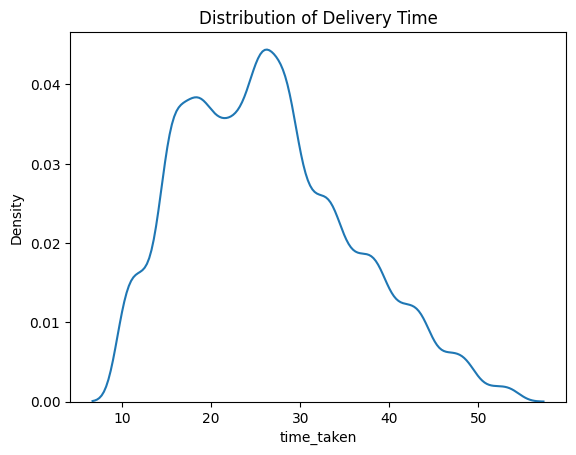

In [17]:
# distribution
sns.kdeplot(df["time_taken"])
plt.title("Distribution of Delivery Time")
plt.show()

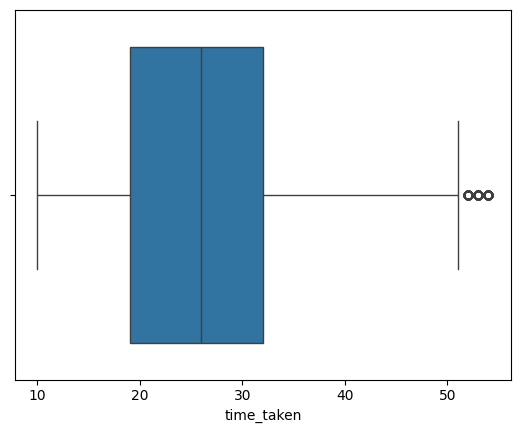

In [18]:
# outliers
sns.boxplot(x=df["time_taken"])
plt.show()

In [19]:
for col in df.columns:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].unique())


age: 20 unique values
[37. 34. 23. 38. 32. 22. 33. 35. 36. 21. 24. 29. 25. 31. 27. 26. 20. nan
 28. 39. 30.]

ratings: 26 unique values
[4.9 4.5 4.4 4.7 4.6 4.8 4.2 4.3 4.  4.1 5.  3.5 nan 3.8 3.9 3.7 2.6 2.5
 3.6 3.1 2.7 3.2 3.3 3.4 2.8 2.9 3. ]

restaurant_latitude: 388 unique values
[22.745049 12.913041 12.914264 11.003669 12.972793 17.431668 23.369746
 12.352058 17.433809 30.327968 10.003064 18.56245  30.899584 26.463504
 19.176269 12.311072 18.592718 17.426228 22.552672 18.563934 23.357804
 12.986047 19.221315 13.005801 26.849596 21.160522 12.934179 18.51421
 11.022477 21.160437 15.51315  15.561295       nan 18.55144  18.593481
 21.173343 17.451976 12.972532 13.064181 19.121999 21.149569 19.091458
 22.539129 12.970324 21.175975 11.003681 10.96185  27.165108 26.88842
 26.913987 12.3085   21.183434 19.254567 25.449659 30.372202 21.157735
 21.186438 12.935662 17.431477 12.933298 22.311358 12.934365 13.086438
 26.913483 17.411028 18.516216 15.5696   19.876428 12.939496 23.374878
 27.

In [20]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(f"{col}: {len(outliers)} outliers")

age: 0 outliers
ratings: 1132 outliers
restaurant_latitude: 0 outliers
restaurant_longitude: 3258 outliers
delivery_latitude: 0 outliers
delivery_longitude: 3258 outliers
vehicle_condition: 0 outliers
multiple_deliveries: 361 outliers
time_taken: 270 outliers
order_day: 0 outliers
order_month: 13583 outliers
is_weekend: 0 outliers
pickup_time_minutes: 0 outliers
order_time_hour: 430 outliers
distance: 0 outliers


In [21]:
# restaurant_longitude and delivery_longitude having many IQR outliers is expected because longitude represents geographical location.
# order_month cant have otliers. they just have different vaues
# order_time_hour also need not to be treated
# we have to investigate ratings, multiple_deliveries, time_taken
# after verifying with the unique values, we dont treat them as outliers

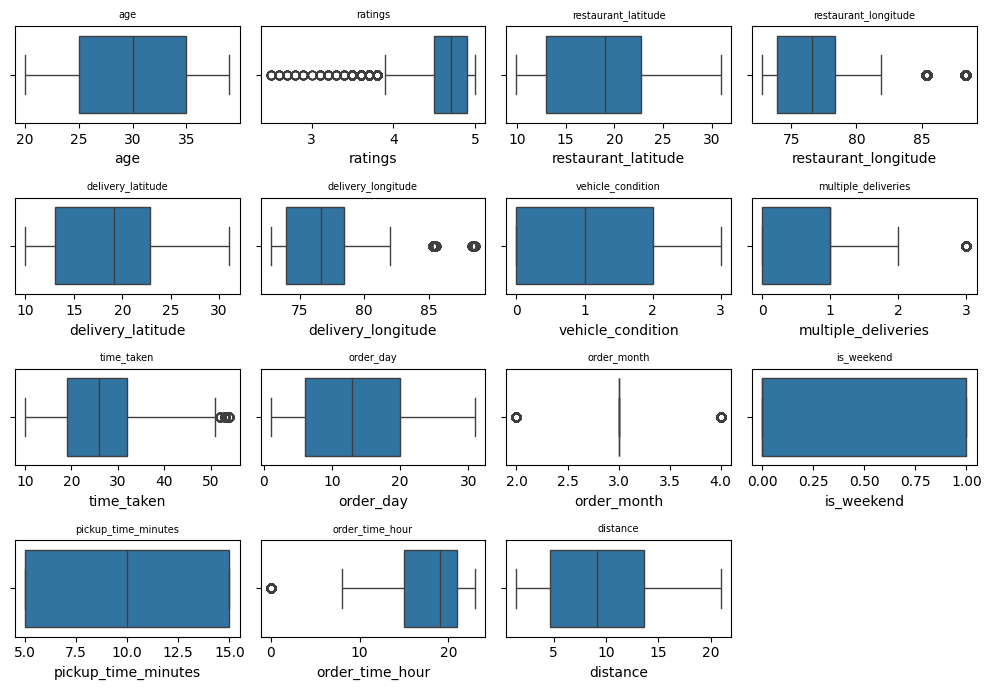

In [22]:
plt.figure(figsize=(10, 7))

for i, col in enumerate(num_cols):
    plt.subplot(4, 4, i + 1)
    sns.boxplot(x=df[col])
    plt.title(col, fontsize=7)

plt.tight_layout()
plt.show()

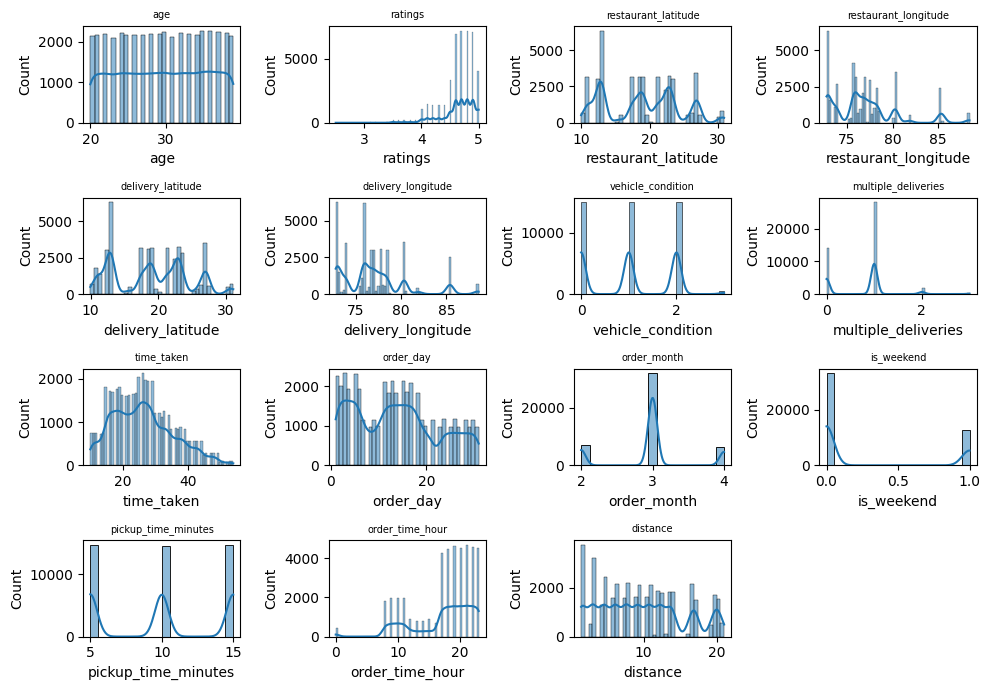

In [23]:
plt.figure(figsize=(10, 7))

for i, col in enumerate(num_cols):
    plt.subplot(4, 4, i+1)
    sns.histplot(x=df[col], kde=True)
    plt.title(col, fontsize=7)

plt.tight_layout()
plt.show()

In [24]:
# skew values
df[num_cols].skew().sort_values()

ratings                -1.793118
order_time_hour        -1.023568
age                    -0.014542
order_month            -0.012456
pickup_time_minutes     0.003900
vehicle_condition       0.060683
restaurant_latitude     0.106518
delivery_latitude       0.107230
order_day               0.299094
multiple_deliveries     0.325004
distance                0.325018
time_taken              0.485582
is_weekend              1.008587
delivery_longitude      1.193275
restaurant_longitude    1.194080
dtype: float64

In [25]:
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].value_counts())


age:
age
35.0    2262
36.0    2260
37.0    2227
30.0    2226
38.0    2219
24.0    2210
32.0    2202
22.0    2196
29.0    2191
33.0    2187
28.0    2179
25.0    2174
34.0    2166
26.0    2159
21.0    2153
27.0    2150
39.0    2144
20.0    2136
31.0    2120
23.0    2087
Name: count, dtype: int64

ratings:
ratings
4.8    7148
4.7    7142
4.9    7041
4.6    6940
5.0    3996
4.5    3303
4.1    1430
4.2    1418
4.3    1409
4.4    1361
4.0    1077
3.5     249
3.8     228
3.7     225
3.6     207
3.9     197
3.4      32
3.1      29
3.2      29
3.3      25
2.7      22
2.6      22
2.5      20
2.8      19
2.9      19
3.0       6
Name: count, dtype: int64

restaurant_latitude:
restaurant_latitude
26.911378    182
26.914142    181
26.902940    177
26.892312    176
26.902908    176
            ... 
9.988483      30
30.873988     30
19.874449     30
23.218998     29
9.960846      29
Name: count, Length: 388, dtype: int64

restaurant_longitude:
restaurant_longitude
75.789034    182
75.805704    181
75

# without pipelines

## Handling Missing Values

In [58]:
df.isna().sum()

age                     1854
ratings                 1908
restaurant_latitude     3630
restaurant_longitude    3630
delivery_latitude       3630
delivery_longitude      3630
weather                  525
traffic                  510
vehicle_condition          0
type_of_order              0
type_of_vehicle            0
multiple_deliveries      993
festival                 228
city_type               1198
time_taken                 0
city_name                  0
order_day                  0
order_month                0
order_day_of_week          0
is_weekend                 0
pickup_time_minutes     1640
order_time_hour         1640
order_time_of_day          0
distance                3630
dtype: int64

In [59]:
num_cols_missing = df.select_dtypes(include='number').columns[df.select_dtypes(include='number').isnull().any()]
num_cols_missing

Index(['age', 'ratings', 'restaurant_latitude', 'restaurant_longitude',
       'delivery_latitude', 'delivery_longitude', 'multiple_deliveries',
       'pickup_time_minutes', 'order_time_hour', 'distance'],
      dtype='object')

In [60]:
cat_cols_missing = df.select_dtypes(include='object').columns[df.select_dtypes(include='object').isnull().any()]
cat_cols_missing

Index(['weather', 'traffic', 'festival', 'city_type'], dtype='object')

In [61]:
# without pipelines

# for categorical data:

mode_imputer = SimpleImputer(strategy = 'most_frequent')
df[cat_cols_missing] = mode_imputer.fit_transform(df[cat_cols_missing])

# for numerical data:
"""
age: 0 outliers                     ->  has missing
ratings: 1132 outliers              ->  has missing
restaurant_latitude: 0 outliers     ->  has missing
restaurant_longitude: 3258 outliers ->  has missing
delivery_latitude: 0 outliers       ->  has missing
delivery_longitude: 3258 outliers   ->  has missing
vehicle_condition: 0 outliers
multiple_deliveries: 361 outliers   ->  has missing
time_taken: 270 outliers
order_day: 0 outliers
order_month: 13583 outliers
is_weekend: 0 outliers
pickup_time_minutes: 0 outliers     ->  has missing
order_time_hour: 430 outliers       ->  has missing
distance: 0 outliers                ->  has missing
"""

mean_cols = [
    'age',
    'pickup_time_minutes',
    'distance'
]

mean_imputer = SimpleImputer(strategy='mean')

df[mean_cols] = mean_imputer.fit_transform(df[mean_cols])


median_cols = [
    'restaurant_latitude',
    'restaurant_longitude',
    'delivery_latitude',
    'delivery_longitude',
    'ratings',
    'multiple_deliveries',
    'order_time_hour'
]

median_imputer = SimpleImputer(strategy='median')

df[median_cols] = median_imputer.fit_transform(df[median_cols])

In [62]:
df.isna().sum()

age                     0
ratings                 0
restaurant_latitude     0
restaurant_longitude    0
delivery_latitude       0
delivery_longitude      0
weather                 0
traffic                 0
vehicle_condition       0
type_of_order           0
type_of_vehicle         0
multiple_deliveries     0
festival                0
city_type               0
time_taken              0
city_name               0
order_day               0
order_month             0
order_day_of_week       0
is_weekend              0
pickup_time_minutes     0
order_time_hour         0
order_time_of_day       0
distance                0
dtype: int64

## Encoding

In [63]:
cat_cols

Index(['weather', 'traffic', 'type_of_order', 'type_of_vehicle', 'festival',
       'city_type', 'city_name', 'order_day_of_week', 'order_time_of_day'],
      dtype='object')

In [64]:
for col in cat_cols:
    print(f"\n{col}:")
    print("Number of unique values:", df[col].nunique())
    print(df[col].unique())


weather:
Number of unique values: 6
['sunny' 'stormy' 'sandstorms' 'cloudy' 'fog' 'windy']

traffic:
Number of unique values: 4
['high' 'jam' 'low' 'medium']

type_of_order:
Number of unique values: 4
['snack' 'drinks' 'buffet' 'meal']

type_of_vehicle:
Number of unique values: 4
['motorcycle' 'scooter' 'electric_scooter' 'bicycle']

festival:
Number of unique values: 2
['no' 'yes']

city_type:
Number of unique values: 3
['urban' 'metropolitian' 'semi-urban']

city_name:
Number of unique values: 22
['INDO' 'BANG' 'COIMB' 'CHEN' 'HYD' 'RANCHI' 'MYS' 'DEH' 'KOC' 'PUNE'
 'LUDH' 'KNP' 'MUM' 'KOL' 'JAP' 'SUR' 'GOA' 'AURG' 'AGR' 'VAD' 'ALH' 'BHP']

order_day_of_week:
Number of unique values: 7
['saturday' 'friday' 'tuesday' 'monday' 'sunday' 'wednesday' 'thursday']

order_time_of_day:
Number of unique values: 5
['morning' 'evening' 'afternoon' 'night' 'after_midnight']


In [65]:
one_hot_cols = ['weather', 'type_of_order', 'type_of_vehicle', 'festival', 'city_type', 'city_name', 'order_day_of_week', 'order_time_of_day']
ordinal_cols = ['traffic']

In [66]:
# nominal encoding
ohe = OneHotEncoder(dtype='int', drop='first')

encoded = pd.DataFrame(
    ohe.fit_transform(df[one_hot_cols]).toarray(),
    columns=ohe.get_feature_names_out(one_hot_cols),
    index=df.index
)

df = pd.concat(
    [df.drop(one_hot_cols, axis=1), encoded],
    axis=1
)

In [68]:
# ordinal encoding
traffic_order = ['low', 'medium', 'high', 'jam']

oe = OrdinalEncoder(
    dtype='int',
    categories=[traffic_order]
)

df[['traffic']] = oe.fit_transform(df[['traffic']])

In [69]:
df

,age,ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,traffic,vehicle_condition,multiple_deliveries,time_taken,...,order_day_of_week_monday,order_day_of_week_saturday,order_day_of_week_sunday,order_day_of_week_thursday,order_day_of_week_tuesday,order_day_of_week_wednesday,order_time_of_day_afternoon,order_time_of_day_evening,order_time_of_day_morning,order_time_of_day_night
0,37.0,4.9,22.745049,75.892471,22.765049,75.912471,2,2,0.0,24,...,0,1,0,0,0,0,0,0,1,0
1,34.0,4.5,12.913041,77.683237,13.043041,77.813237,3,2,1.0,33,...,0,0,0,0,0,0,0,1,0,0
2,23.0,4.4,12.914264,77.678400,12.924264,77.688400,0,0,1.0,26,...,0,1,0,0,0,0,0,0,1,0
3,38.0,4.7,11.003669,76.976494,11.053669,77.026494,1,0,1.0,21,...,0,0,0,0,1,0,0,1,0,0
4,32.0,4.6,12.972793,80.249982,13.012793,80.289982,2,1,1.0,30,...,0,1,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45497,30.0,4.8,26.902328,75.794257,26.912328,75.804257,2,1,0.0,32,...,0,0,0,1,0,0,0,0,1,0
45498,21.0,4.6,19.065838,76.618203,19.124049,76.662620,3,0,1.0,36,...,0,0,0,0,0,1,0,1,0,0
45499,30.0,4.9,13.022394,80.242439,13.052394,80.272439,0,1,0.0,16,...,0,0,0,0,0,0,0,0,0,1
45500,20.0,4.7,11.001753,76.986241,11.041753,77.026241,2,0,1.0,26,...,1,0,0,0,0,0,1,0,0,0


## scaling

In [74]:
df.columns

Index(['age', 'ratings', 'restaurant_latitude', 'restaurant_longitude',
       'delivery_latitude', 'delivery_longitude', 'traffic',
       'vehicle_condition', 'multiple_deliveries', 'time_taken', 'order_day',
       'order_month', 'is_weekend', 'pickup_time_minutes', 'order_time_hour',
       'distance', 'weather_fog', 'weather_sandstorms', 'weather_stormy',
       'weather_sunny', 'weather_windy', 'type_of_order_drinks',
       'type_of_order_meal', 'type_of_order_snack',
       'type_of_vehicle_electric_scooter', 'type_of_vehicle_motorcycle',
       'type_of_vehicle_scooter', 'festival_yes', 'city_type_semi-urban',
       'city_type_urban', 'city_name_ALH', 'city_name_AURG', 'city_name_BANG',
       'city_name_BHP', 'city_name_CHEN', 'city_name_COIMB', 'city_name_DEH',
       'city_name_GOA', 'city_name_HYD', 'city_name_INDO', 'city_name_JAP',
       'city_name_KNP', 'city_name_KOC', 'city_name_KOL', 'city_name_LUDH',
       'city_name_MUM', 'city_name_MYS', 'city_name_PUNE', 'city

In [75]:
# we dont have to scale 'time_taken' as it is as target
# and also columns that have 0/1 also need not be encoded

In [76]:
scale_cols = ['age', 'ratings', 'restaurant_latitude', 'restaurant_longitude', 'delivery_latitude', 'delivery_longitude', 'multiple_deliveries', 'order_day', 'order_month', 'pickup_time_minutes', 'order_time_hour', 'distance']

In [77]:
scaler = RobustScaler()
df[scale_cols] = scaler.fit_transform(df[scale_cols])

In [78]:
df

,age,ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,traffic,vehicle_condition,multiple_deliveries,time_taken,...,order_day_of_week_monday,order_day_of_week_saturday,order_day_of_week_sunday,order_day_of_week_thursday,order_day_of_week_tuesday,order_day_of_week_wednesday,order_time_of_day_afternoon,order_time_of_day_evening,order_time_of_day_morning,order_time_of_day_night
0,0.827221,1.0,0.379182,-0.175691,0.375787,-0.183013,2,2,-1.0,24,...,0,1,0,0,0,0,0,0,1,0
1,0.493888,-1.0,-0.634111,0.257831,-0.627620,0.280715,3,2,0.0,33,...,0,0,0,0,0,0,0,1,0,0
2,-0.728334,-1.5,-0.633985,0.256660,-0.639879,0.250259,0,0,0.0,26,...,0,1,0,0,0,0,0,0,1,0
3,0.938332,0.0,-0.830892,0.086738,-0.832942,0.088774,1,0,0.0,21,...,0,0,0,0,1,0,0,1,0,0
4,0.271666,-0.5,-0.627953,0.879208,-0.630742,0.884965,2,1,0.0,30,...,0,1,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45497,0.049444,0.5,0.807634,-0.199467,0.803827,-0.209414,2,1,-1.0,32,...,0,0,0,1,0,0,0,0,1,0
45498,-0.950556,-0.5,0.000000,0.000000,0.000000,0.000000,3,0,0.0,36,...,0,0,0,0,0,1,0,1,0,0
45499,0.049444,1.0,-0.622841,0.877382,-0.626654,0.880686,0,1,-1.0,16,...,0,0,0,0,0,0,0,0,0,1
45500,-1.061668,0.0,-0.831090,0.089097,-0.834172,0.088712,2,0,0.0,26,...,1,0,0,0,0,0,1,0,0,0


In [79]:
df.skew()

age                           -0.014847
ratings                       -1.853135
restaurant_latitude            0.104088
restaurant_longitude           1.265191
delivery_latitude              0.105081
                                 ...   
order_day_of_week_wednesday    1.901046
order_time_of_day_afternoon    2.887224
order_time_of_day_evening      0.907207
order_time_of_day_morning      1.760693
order_time_of_day_night        0.397884
Length: 61, dtype: float64

# with pipelines

In [24]:
df

,age,ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,weather,traffic,vehicle_condition,type_of_order,...,time_taken,city_name,order_day,order_month,order_day_of_week,is_weekend,pickup_time_minutes,order_time_hour,order_time_of_day,distance
0,37.0,4.9,22.745049,75.892471,22.765049,75.912471,sunny,high,2,snack,...,24,INDO,19,3,saturday,1,15.0,11.0,morning,3.025149
1,34.0,4.5,12.913041,77.683237,13.043041,77.813237,stormy,jam,2,snack,...,33,BANG,25,3,friday,0,5.0,19.0,evening,20.183530
2,23.0,4.4,12.914264,77.678400,12.924264,77.688400,sandstorms,low,0,drinks,...,26,BANG,19,3,saturday,1,15.0,8.0,morning,1.552758
3,38.0,4.7,11.003669,76.976494,11.053669,77.026494,sunny,medium,0,buffet,...,21,COIMB,5,4,tuesday,0,10.0,18.0,evening,7.790401
4,32.0,4.6,12.972793,80.249982,13.012793,80.289982,cloudy,high,1,snack,...,30,CHEN,26,3,saturday,1,15.0,13.0,afternoon,6.210138
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45497,30.0,4.8,26.902328,75.794257,26.912328,75.804257,windy,high,1,meal,...,32,JAP,24,3,thursday,0,10.0,11.0,morning,1.489846
45498,21.0,4.6,NaN,NaN,NaN,NaN,windy,jam,0,buffet,...,36,AGR,16,2,wednesday,0,15.0,19.0,evening,NaN
45499,30.0,4.9,13.022394,80.242439,13.052394,80.272439,cloudy,low,1,drinks,...,16,CHEN,11,3,friday,0,15.0,23.0,night,4.657195
45500,20.0,4.7,11.001753,76.986241,11.041753,77.026241,cloudy,high,0,snack,...,26,COIMB,7,3,monday,0,5.0,13.0,afternoon,6.232393


In [25]:
X = df.drop('time_taken', axis=1)
y = df['time_taken']

In [26]:
# Columns where we want mean imputation
mean_cols = [
    'age',
    'pickup_time_minutes',
    'distance'
]

# Columns where we want median imputation
median_cols = [
    'restaurant_latitude',
    'restaurant_longitude',
    'delivery_latitude',
    'delivery_longitude',
    'ratings',
    'multiple_deliveries',
    'order_time_hour'
]

# Numerical columns with no missing values
other_num_cols = [
    'vehicle_condition',
    'order_day',
    'order_month',
    'is_weekend'
]

# Nominal categorical columns
one_hot_cols = [
    'weather',
    'type_of_order',
    'type_of_vehicle',
    'festival',
    'city_type',
    'city_name',
    'order_day_of_week',
    'order_time_of_day'
]

# Ordinal categorical column
ordinal_cols = [
    'traffic'
]

# numerical columns for knn imputation
num_cols = (
    mean_cols +
    median_cols +
    other_num_cols
)

In [27]:
'''# Numerical Pipeline - Mean
mean_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', RobustScaler())
])


# Numerical Pipeline - Median
median_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])


# Numerical Pipeline - No missing values
other_num_pipeline = Pipeline([
    ('scaler', RobustScaler())
])
'''

# Nominal categorical Pipeline
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='first'
    ))
])


# Ordinal categorical Pipeline

traffic_order = ['low','medium','high','jam']

ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=[traffic_order],
        dtype=int
    ))
])

# Numerical Pipeline - KNN Imputation
num_pipeline = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', RobustScaler())
])

In [28]:
preprocessor = ColumnTransformer([
    ('cat', cat_pipeline, one_hot_cols),
    ('ord', ordinal_pipeline, ordinal_cols),
    ('num', num_pipeline, num_cols)
])
'''('mean_num', mean_pipeline, mean_cols),
    ('median_num', median_pipeline, median_cols),
    ('other_num', other_num_pipeline, other_num_cols),'''

"('mean_num', mean_pipeline, mean_cols),\n    ('median_num', median_pipeline, median_cols),\n    ('other_num', other_num_pipeline, other_num_cols),"

In [29]:
preprocessor

,transformers,"[('cat', ...), ('ord', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None


In [30]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2,random_state=42)

In [31]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

In [32]:
# Transform test data
X_test_processed = preprocessor.transform(X_test)

In [33]:
print("Original X_train shape:", X_train.shape)
print("Processed X_train shape:", X_train_processed.shape)

print("Original X_test shape:", X_test.shape)
print("Processed X_test shape:", X_test_processed.shape)

Original X_train shape: (36401, 23)
Processed X_train shape: (36401, 60)
Original X_test shape: (9101, 23)
Processed X_test shape: (9101, 60)


# feature selection

In [36]:
# check for duplicate cols

In [37]:
df.T.duplicated().sum()

np.int64(0)

In [34]:
from sklearn.feature_selection import SelectKBest, f_regression

skb = SelectKBest(
    score_func=f_regression, k=30
)

X_train_selected = skb.fit_transform(
    X_train_processed,
    y_train
)

X_test_selected = skb.transform(
    X_test_processed
)

print("Before:", X_train_processed.shape)
print("After:", X_train_selected.shape)

Before: (36401, 60)
After: (36401, 30)


In [35]:
from mlxtend.feature_selection import ExhaustiveFeatureSelector

In [36]:
# GET FEATURE NAMES

feature_names = preprocessor.get_feature_names_out()

feature_names


array(['cat__weather_fog', 'cat__weather_sandstorms',
       'cat__weather_stormy', 'cat__weather_sunny', 'cat__weather_windy',
       'cat__type_of_order_drinks', 'cat__type_of_order_meal',
       'cat__type_of_order_snack',
       'cat__type_of_vehicle_electric_scooter',
       'cat__type_of_vehicle_motorcycle', 'cat__type_of_vehicle_scooter',
       'cat__festival_yes', 'cat__city_type_semi-urban',
       'cat__city_type_urban', 'cat__city_name_ALH',
       'cat__city_name_AURG', 'cat__city_name_BANG', 'cat__city_name_BHP',
       'cat__city_name_CHEN', 'cat__city_name_COIMB',
       'cat__city_name_DEH', 'cat__city_name_GOA', 'cat__city_name_HYD',
       'cat__city_name_INDO', 'cat__city_name_JAP', 'cat__city_name_KNP',
       'cat__city_name_KOC', 'cat__city_name_KOL', 'cat__city_name_LUDH',
       'cat__city_name_MUM', 'cat__city_name_MYS', 'cat__city_name_PUNE',
       'cat__city_name_RANCHI', 'cat__city_name_SUR',
       'cat__city_name_VAD', 'cat__order_day_of_week_monday',
  

In [37]:

# FEATURE SCORES

feature_scores = pd.DataFrame({
    'Feature': feature_names,
    'Score': skb.scores_
})

feature_scores = feature_scores.sort_values(
    by='Score',
    ascending=False
)

print("\nTop 30 Features:")
print(feature_scores.head(30).to_string(index=False))


Top 30 Features:
                              Feature       Score
                         ord__traffic 7327.999558
             num__multiple_deliveries 6224.508964
                         num__ratings 5234.529189
                        num__distance 4255.789716
                             num__age 3481.931135
                    cat__festival_yes 3404.522409
       cat__order_time_of_day_morning 2301.024589
               num__vehicle_condition 2163.920060
                   cat__weather_sunny 1657.603041
                 cat__city_type_urban 1363.487428
                 num__order_time_hour 1310.818265
      cat__type_of_vehicle_motorcycle 1017.290780
       cat__order_time_of_day_evening  878.467527
            cat__city_type_semi-urban  811.858442
         cat__type_of_vehicle_scooter  708.425082
                     cat__weather_fog  574.833559
     cat__order_day_of_week_wednesday  176.201156
         cat__order_time_of_day_night  151.373988
cat__type_of_vehicle_electric_sc

# model building

In [38]:
lr = LinearRegression()

dt = DecisionTreeRegressor(random_state=42)
rf = RandomForestRegressor(random_state=42)
gb = GradientBoostingRegressor(random_state=42)

xgb = XGBRegressor(random_state=42)
#ridge = Ridge()
#lasso = Lasso()
#elastic = ElasticNet()

#knn = KNeighborsRegressor()
#svr = SVR()

In [39]:
models = [
    lr,
    dt,
    rf,
    gb
]
#ridge,
#lasso,
#elastic,
#knn
#svr

In [ ]:
for model in models:
    model.fit(X_train_selected, y_train)

In [40]:
xgb.fit(X_train_selected, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [41]:
model_names = [
    'Linear Regression',
    'Decision Tree',
    'Random Forest',
    'Gradient Boosting'
]
#'Ridge',
#'Lasso',
#'Elastic Net',
#'KNN',
#'SVR'

In [ ]:
'''results = []

for name, model in zip(model_names, models):

    y_pred = model.predict(X_test_selected)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'RMSE': rmse,
        'R2': r2
    })

results_df = pd.DataFrame(results)

results_df['RMSE'] = results_df['RMSE'].round(4)
results_df['R2'] = results_df['R2'].round(4)'''

In [46]:
results_df

,Model,RMSE,R2
0,Linear Regression,6.0881,0.5786
1,Decision Tree,5.6319,0.6394
2,Random Forest,4.1385,0.8053
3,Gradient Boosting,4.6947,0.7494


In [43]:
y_pred = xgb.predict(X_test_selected)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("XGBoost")
print("RMSE:", rmse)
print("R2:", r2)

XGBoost
RMSE: 4.095610916344004
R2: 0.8093015551567078


# Cross validation

In [44]:
cv_results = []

for model, model_name in zip( models, model_names):

    scores = cross_val_score(
        model,
        X_train_selected,
        y_train,
        cv=5,
        scoring='neg_root_mean_squared_error'
    )

    rmse_scores = -scores

    cv_results.append({
        'Model': model_name,
        'Mean RMSE': rmse_scores.mean(),
        'Std RMSE': rmse_scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df['Mean RMSE'] = cv_results_df['Mean RMSE'].round(4)
cv_results_df['Std RMSE'] = cv_results_df['Std RMSE'].round(4)

NameError: name 'models' is not defined

In [ ]:
cv_results_df

In [44]:
# RMSE

rmse_scores = cross_val_score(
    xgb,
    X_train_selected,
    y_train,
    cv=5,
    scoring='neg_root_mean_squared_error'
)

rmse_scores = -rmse_scores

# R2
r2_scores = cross_val_score(
    xgb,
    X_train_selected,
    y_train,
    cv=5,
    scoring='r2'
)

print("XGBoost Cross-Validation RMSE Scores:")
print(rmse_scores)

print("Mean RMSE:", rmse_scores.mean())
print("Standard Deviation RMSE:", rmse_scores.std())

print("\nXGBoost Cross-Validation R2 Scores:")
print(r2_scores)

print("Mean R2:", r2_scores.mean())
print("Standard Deviation R2:", r2_scores.std())

XGBoost Cross-Validation RMSE Scores:
[4.14787388 4.08393192 4.10196543 4.12826252 4.11587715]
Mean RMSE: 4.1155821800231935
Standard Deviation RMSE: 0.02186680837392507

XGBoost Cross-Validation R2 Scores:
[0.80584884 0.81003809 0.80983078 0.80691934 0.80640042]
Mean R2: 0.8078074932098389
Standard Deviation R2: 0.0017705528427880352


# Hyperparameter Tuning

In [45]:
param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

In [46]:
random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_selected, y_train)

,estimator,"XGBRegressor(...ree=None, ...)"
,param_distributions,"{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'n_estimators': [100, 200, ...], ...}"
,n_iter,20
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [47]:
print("Best Parameters:")
print(random_search.best_params_)

Best Parameters:
{'subsample': 0.8, 'n_estimators': 500, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


In [48]:
print("Best CV RMSE:")
print(-random_search.best_score_)

Best CV RMSE:
4.04313383102417


In [49]:
best_xgb = random_search.best_estimator_

In [50]:
y_pred = best_xgb.predict(X_test_selected)

In [53]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Tuned XGBoost")
print("RMSE:", rmse)
print("R2:", r2)

Tuned XGBoost
RMSE: 4.020544697312285
R2: 0.816227912902832


In [54]:
def Objective(trial):

    # creating search space
    n_estimators = trial.suggest_int('n_estimators', 100, 500)
    max_depth = trial.suggest_int('max_depth', 3, 10)
    learning_rate = trial.suggest_float('learning_rate', 0.01, 0.2)
    subsample = trial.suggest_float('subsample', 0.7, 1.0)
    colsample_bytree = trial.suggest_float('colsample_bytree', 0.7, 1.0)

    # train the model
    xgb = XGBRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        random_state=42
    )

    kf = KFold(
        n_splits=5,
        shuffle=True,
        random_state=23
    )

    # scoring
    score = cross_val_score(
        xgb,
        X_train_selected,
        y_train,
        cv=kf,
        scoring='neg_root_mean_squared_error'
    ).mean()

    return -score


study = optuna.create_study(
    direction='minimize'
)

study.optimize(
    Objective,
    n_trials=10
)

[I 2026-10-04 19:53:02,790] A new study created in memory with name: no-name-18c76a6b-70b3-4e22-bf76-8fb02514e969
[I 2026-10-04 19:53:07,340] Trial 0 finished with value: 4.182445621490478 and parameters: {'n_estimators': 166, 'max_depth': 8, 'learning_rate': 0.01857972655983978, 'subsample': 0.7445591152918062, 'colsample_bytree': 0.8604268570474086}. Best is trial 0 with value: 4.182445621490478.
[I 2026-10-04 19:53:13,908] Trial 1 finished with value: 4.035289239883423 and parameters: {'n_estimators': 321, 'max_depth': 7, 'learning_rate': 0.03506818407536033, 'subsample': 0.9729603763987275, 'colsample_bytree': 0.724189562845927}. Best is trial 1 with value: 4.035289239883423.
[I 2026-10-04 19:53:24,958] Trial 2 finished with value: 4.146801280975342 and parameters: {'n_estimators': 174, 'max_depth': 10, 'learning_rate': 0.11262575723828927, 'subsample': 0.746079526046318, 'colsample_bytree': 0.7955069572421335}. Best is trial 1 with value: 4.035289239883423.
[I 2026-10-04 19:53:46,

In [55]:
print("Best RMSE:", study.best_value)
print("Best Parameters:")
print(study.best_params)

Best RMSE: 4.035289239883423
Best Parameters:
{'n_estimators': 321, 'max_depth': 7, 'learning_rate': 0.03506818407536033, 'subsample': 0.9729603763987275, 'colsample_bytree': 0.724189562845927}


In [59]:
best_parameters = study.best_params

In [60]:
from xgboost import XGBRegressor

best_xgb_optuna = XGBRegressor(
    **best_parameters,
    random_state=42,
    n_jobs=-1
)

In [61]:
best_xgb_optuna.fit(X_train_selected, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.724189562845927
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [62]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

y_pred = best_xgb_optuna.predict(X_test_selected)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Optuna Tuned XGBoost")
print("RMSE:", rmse)
print("R2:", r2)

Optuna Tuned XGBoost
RMSE: 4.0192436804930844
R2: 0.8163468241691589


In [63]:
'''# using all featres without feature selection
xgb_all = XGBRegressor(
    random_state=42,
    subsample=0.8,
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    colsample_bytree=0.8
)

xgb_all.fit(X_train_processed, y_train)

y_pred_all = xgb_all.predict(X_test_processed)

rmse_all = np.sqrt(mean_squared_error(y_test, y_pred_all))
r2_all = r2_score(y_test, y_pred_all)

print("XGBoost using all features")
print("RMSE:", rmse_all)
print("R2:", r2_all)'''

'# using all featres without feature selection\nxgb_all = XGBRegressor(\n    random_state=42,\n    subsample=0.8,\n    n_estimators=500,\n    max_depth=8,\n    learning_rate=0.05,\n    colsample_bytree=0.8\n)\n\nxgb_all.fit(X_train_processed, y_train)\n\ny_pred_all = xgb_all.predict(X_test_processed)\n\nrmse_all = np.sqrt(mean_squared_error(y_test, y_pred_all))\nr2_all = r2_score(y_test, y_pred_all)\n\nprint("XGBoost using all features")\nprint("RMSE:", rmse_all)\nprint("R2:", r2_all)'

In [64]:
y_train_pred = best_xgb_optuna.predict(X_train_selected)
y_test_pred = best_xgb_optuna.predict(X_test_selected)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training Performance")
print("RMSE:", train_rmse)
print("R2:", train_r2)

print("\nTesting Performance")
print("RMSE:", test_rmse)
print("R2:", test_r2)

Training Performance
RMSE: 3.5751534329013936
R2: 0.8549763560295105

Testing Performance
RMSE: 4.0192436804930844
R2: 0.8163468241691589


In [66]:
import joblib

joblib.dump(preprocessor, "preprocessor.pkl")
joblib.dump(skb, "feature_selector.pkl")
joblib.dump(best_parameters, "best_params.pkl")

['best_params.pkl']